In [ ]:
# Courtesy of Fable 5.2. A supplement to minimal_eda.ipynb.

# Bike Sharing (UCI id=275) — Exploratory Data Analysis

Minimal, fundamental EDA of the hourly Capital Bikeshare dataset ahead of a regression / forecasting project.

**Scope**: inspect the `fetch_ucirepo` object, verify schema and integrity, characterize the target, check the time axis, look at the main drivers, and record issues that matter for modeling. No modeling, no feature engineering.

Source: [UCI Machine Learning Repository, Bike Sharing Dataset](https://archive.ics.uci.edu/dataset/275/bike+sharing+dataset), Fanaee-T & Gama (2013).

In [1]:
# !pip install ucimlrepo
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from ucimlrepo import fetch_ucirepo

pd.set_option("display.width", 120)
pd.set_option("display.max_colwidth", 80)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

bike_sharing = fetch_ucirepo(id=275)
X = bike_sharing.data.features
y = bike_sharing.data.targets

## 1. The returned object

`fetch_ucirepo` returns a dict-like object with three top-level keys. `data` holds the pandas frames, split by variable role; `metadata` and `variables` hold the documentation.

In [2]:
print("top-level keys :", list(bike_sharing.keys()))
print("data keys      :", list(bike_sharing.data.keys()))
print()
for k in ["ids", "features", "targets", "original"]:
    df = bike_sharing.data[k]
    print(f"data.{k:<9} shape={df.shape}  columns={list(df.columns)}")

top-level keys : ['data', 'metadata', 'variables']
data keys      : ['ids', 'features', 'targets', 'original', 'headers']

data.ids       shape=(17379, 1)  columns=['instant']
data.features  shape=(17379, 13)  columns=['dteday', 'season', 'yr', 'mnth', 'hr', 'holiday', 'weekday', 'workingday', 'weathersit', 'temp', 'atemp', 'hum', 'windspeed']
data.targets   shape=(17379, 1)  columns=['cnt']
data.original  shape=(17379, 17)  columns=['instant', 'dteday', 'season', 'yr', 'mnth', 'hr', 'holiday', 'weekday', 'workingday', 'weathersit', 'temp', 'atemp', 'hum', 'windspeed', 'casual', 'registered', 'cnt']


In [ ]:
m = bike_sharing.metadata
pd.Series(
    {
        k: m[k]
        for k in [
            "name",
            "uci_id",
            "num_instances",
            "num_features",
            "tasks",
            "target_col",
            "index_col",
            "has_missing_values",
            "last_updated",
            "dataset_doi",
        ]
    }
).to_frame("metadata")

,metadata
name,Bike Sharing
uci_id,275
num_instances,17389
num_features,13
tasks,[Regression]
target_col,[cnt]
index_col,[instant]
has_missing_values,no
last_updated,Sun Mar 10 2024
dataset_doi,10.24432/C5W894


Variable roles and documented meanings. Note the declared types: most integer columns are **categorical** codes, not numeric quantities.

In [ ]:
bike_sharing.variables[
    ["name", "role", "type", "description", "units", "missing_values"]
]

,name,role,type,description,units,missing_values
0,instant,ID,Integer,record index,NaN,no
1,dteday,Feature,Date,date,NaN,no
2,season,Feature,Categorical,"1:winter, 2:spring, 3:summer, 4:fall",NaN,no
3,yr,Feature,Categorical,"year (0: 2011, 1: 2012)",NaN,no
4,mnth,Feature,Categorical,month (1 to 12),NaN,no
5,hr,Feature,Categorical,hour (0 to 23),NaN,no
6,holiday,Feature,Binary,weather day is holiday or not (extracted from http://dchr.dc.gov/page/holida...,NaN,no
7,weekday,Feature,Categorical,day of the week,NaN,no
8,workingday,Feature,Binary,"if day is neither weekend nor holiday is 1, otherwise is 0",NaN,no
9,weathersit,Feature,Categorical,"- 1: Clear, Few clouds, Partly cloudy, Partly cloudy",NaN,no


## 2. Schema and integrity

Work on `data.original` (all 17 columns) so that the `ID` and `Other` columns can be checked too. Parse `dteday` and build a true hourly timestamp.

In [5]:
df = bike_sharing.data.original.copy()
df["dteday"] = pd.to_datetime(df["dteday"])
df["timestamp"] = df["dteday"] + pd.to_timedelta(df["hr"], unit="h")

df.head()

,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt,timestamp
0,1,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0,3,13,16,2011-01-01 00:00:00
1,2,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0,8,32,40,2011-01-01 01:00:00
2,3,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0,5,27,32,2011-01-01 02:00:00
3,4,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.2879,0.75,0.0,3,10,13,2011-01-01 03:00:00
4,5,2011-01-01,1,0,1,4,0,6,0,1,0.24,0.2879,0.75,0.0,0,1,1,2011-01-01 04:00:00


In [ ]:
summary = pd.DataFrame(
    {
        "dtype": df.dtypes.astype(str),
        "n_unique": df.nunique(),
        "n_missing": df.isna().sum(),
        "min": df.min(numeric_only=True),
        "max": df.max(numeric_only=True),
    }
)
summary

,dtype,n_unique,n_missing,min,max
atemp,float64,65,0,0.00,1.0000
casual,int64,322,0,0.00,367.0000
cnt,int64,869,0,1.00,977.0000
dteday,datetime64[us],731,0,NaN,NaN
holiday,int64,2,0,0.00,1.0000
hr,int64,24,0,0.00,23.0000
hum,float64,89,0,0.00,1.0000
instant,int64,17379,0,1.00,17379.0000
mnth,int64,12,0,1.00,12.0000
registered,int64,776,0,0.00,886.0000


In [ ]:
checks = {
    "rows": len(df),
    "duplicate rows": int(df.duplicated().sum()),
    "duplicate timestamps": int(df["timestamp"].duplicated().sum()),
    "instant is 1..n contiguous": bool(
        (df["instant"].values == np.arange(1, len(df) + 1)).all()
    ),
    "timestamps sorted": bool(df["timestamp"].is_monotonic_increasing),
    "cnt == casual + registered": bool(
        (df["cnt"] == df["casual"] + df["registered"]).all()
    ),
    "date range": f"{df['timestamp'].min()} to {df['timestamp'].max()}",
}
pd.Series(checks).to_frame("value")

,value
rows,17379
duplicate rows,0
duplicate timestamps,0
instant is 1..n contiguous,True
timestamps sorted,True
cnt == casual + registered,True
date range,2011-01-01 00:00:00 to 2012-12-31 23:00:00


### Completeness of the hourly grid
`num_instances` is 17,379 but two full years contain 17,544 hours. Quantify the gap.

In [ ]:
full_grid = pd.date_range(df["timestamp"].min(), df["timestamp"].max(), freq="h")
missing_hours = full_grid.difference(df["timestamp"])
gaps = (pd.Series(missing_hours).diff() != pd.Timedelta("1h")).cumsum()
gap_lengths = pd.Series(missing_hours).groupby(gaps.values).size()

print(f"expected hours : {len(full_grid):,}")
print(f"present hours  : {len(df):,}")
print(
    f"missing hours  : {len(missing_hours):,}  ({len(missing_hours) / len(full_grid):.2%})"
)
print(f"contiguous gaps: {len(gap_lengths)}  (longest = {gap_lengths.max()} h)")
print()
print("Longest gaps:")
longest = gap_lengths.sort_values(ascending=False).head(5)
for g, n in longest.items():
    start = pd.Series(missing_hours)[gaps.values == g].min()
    print(f"  {start}  ->  {n} consecutive hours")

expected hours : 17,544
present hours  : 17,379
missing hours  : 165  (0.94%)
contiguous gaps: 75  (longest = 36 h)

Longest gaps:
  2012-10-29 01:00:00  ->  36 consecutive hours
  2011-01-26 18:00:00  ->  22 consecutive hours
  2011-08-27 18:00:00  ->  13 consecutive hours
  2011-01-18 00:00:00  ->  12 consecutive hours
  2011-02-22 00:00:00  ->  6 consecutive hours


## 3. Target: `cnt`

In [9]:
df["cnt"].describe().to_frame("cnt").T.round(1)

,count,mean,std,min,25%,50%,75%,max
cnt,17379.0,189.5,181.4,1.0,40.0,142.0,281.0,977.0


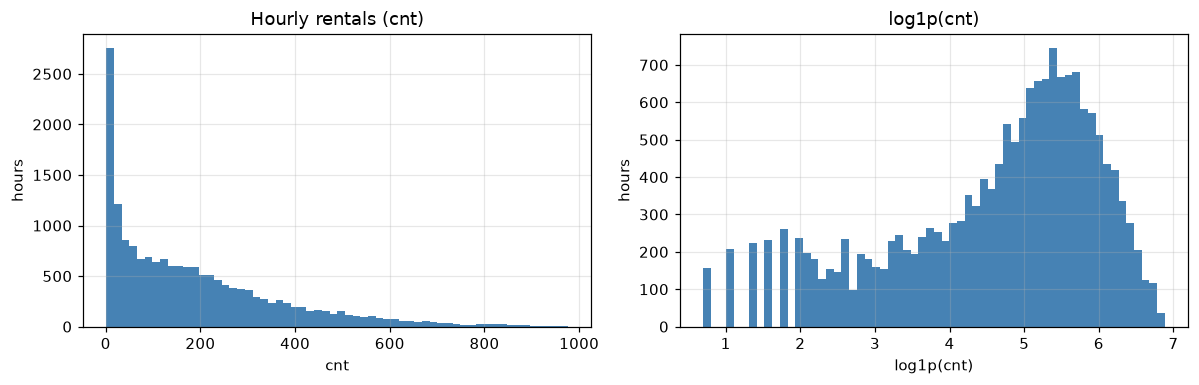

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
axes[0].hist(df["cnt"], bins=60, color="steelblue")
axes[0].set(title="Hourly rentals (cnt)", xlabel="cnt", ylabel="hours")
axes[1].hist(np.log1p(df["cnt"]), bins=60, color="steelblue")
axes[1].set(title="log1p(cnt)", xlabel="log1p(cnt)", ylabel="hours")
plt.tight_layout()

In [11]:
print(f"skewness cnt      : {df['cnt'].skew():.2f}")
print(f"skewness log1p    : {np.log1p(df['cnt']).skew():.2f}")
print(f"zero-count hours  : {(df['cnt'] == 0).sum()}")
print(f"share from casual : {df['casual'].sum() / df['cnt'].sum():.1%}")

skewness cnt      : 1.28
skewness log1p    : -0.82
zero-count hours  : 0
share from casual : 18.8%


## 4. Time structure
Daily aggregate over the full span (trend, seasonality) and the within-day profile split by `workingday`.

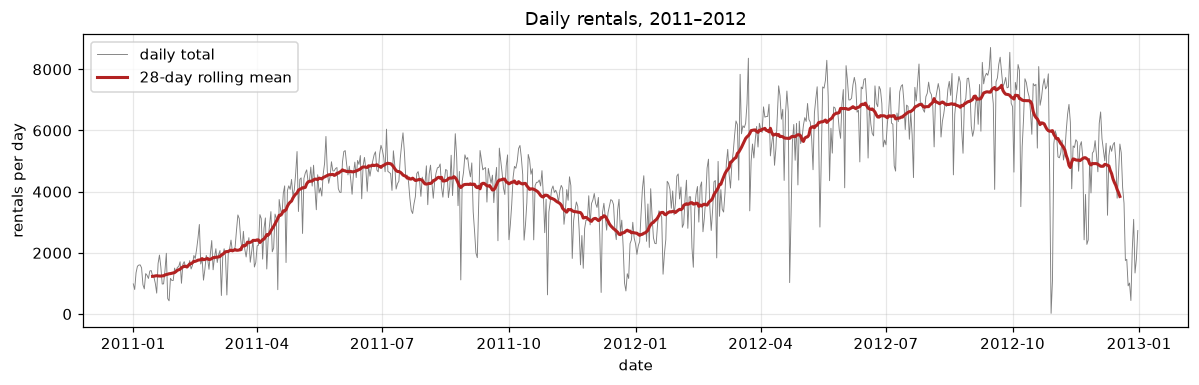

In [ ]:
daily = df.set_index("timestamp")["cnt"].resample("D").sum()
fig, ax = plt.subplots(figsize=(11, 3.6))
ax.plot(daily.index, daily.values, lw=0.6, color="grey", label="daily total")
ax.plot(
    daily.rolling(28, center=True).mean(),
    lw=2,
    color="firebrick",
    label="28-day rolling mean",
)
ax.set(title="Daily rentals, 2011–2012", xlabel="date", ylabel="rentals per day")
ax.legend()
plt.tight_layout()

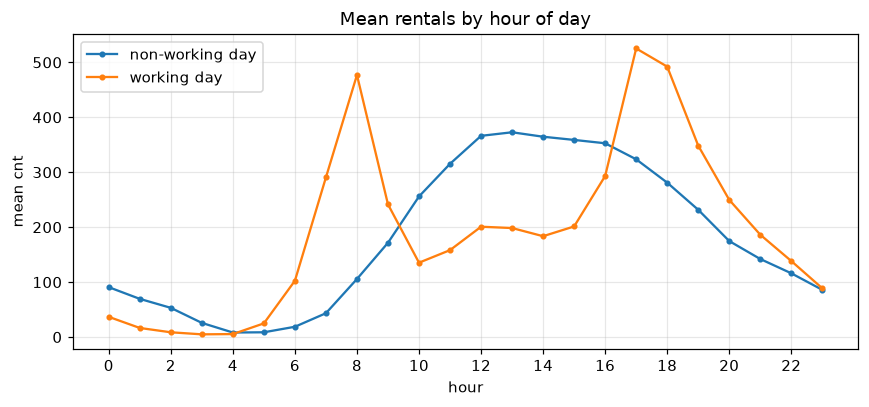

In [ ]:
hourly_profile = df.groupby(["workingday", "hr"])["cnt"].mean().unstack(0)
hourly_profile.columns = ["non-working day", "working day"]

fig, ax = plt.subplots(figsize=(8, 3.8))
hourly_profile.plot(ax=ax, marker="o", ms=3)
ax.set(
    title="Mean rentals by hour of day",
    xlabel="hour",
    ylabel="mean cnt",
    xticks=range(0, 24, 2),
)
plt.tight_layout()

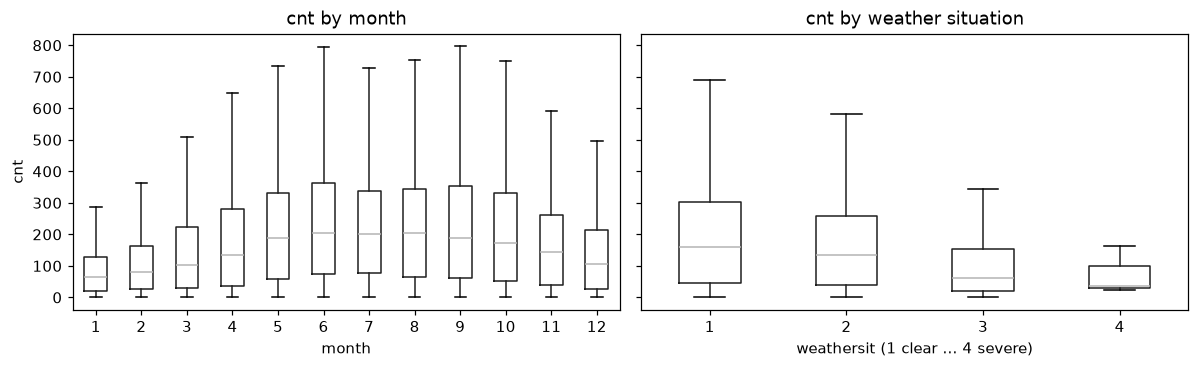

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), sharey=True)
df.boxplot(column="cnt", by="mnth", ax=axes[0], grid=False, showfliers=False)
axes[0].set(title="cnt by month", xlabel="month", ylabel="cnt")
df.boxplot(column="cnt", by="weathersit", ax=axes[1], grid=False, showfliers=False)
axes[1].set(title="cnt by weather situation", xlabel="weathersit (1 clear … 4 severe)")
plt.suptitle("")
plt.tight_layout()

In [15]:
# autocorrelation of the hourly series at daily / weekly lags
acf = {lag: df["cnt"].autocorr(lag) for lag in [1, 2, 3, 6, 12, 24, 48, 168]}
pd.Series(acf, name="autocorr").to_frame().T.round(3)

,1,2,3,6,12,24,48,168
autocorr,0.844,0.594,0.404,0.01,-0.14,0.816,0.678,0.821


## 5. Features

In [ ]:
cat_cols = [
    "season",
    "yr",
    "mnth",
    "hr",
    "holiday",
    "weekday",
    "workingday",
    "weathersit",
]
num_cols = ["temp", "atemp", "hum", "windspeed"]

pd.DataFrame(
    {
        c: df[c].value_counts().sort_index()
        for c in ["season", "yr", "holiday", "workingday", "weathersit"]
    }
).astype("Int64")

,season,yr,holiday,workingday,weathersit
0,<NA>,8645,16879,5514,<NA>
1,4242,8734,500,11865,11413
2,4409,<NA>,<NA>,<NA>,4544
3,4496,<NA>,<NA>,<NA>,1419
4,4232,<NA>,<NA>,<NA>,3


In [17]:
df[num_cols].describe().T.round(3)

,count,mean,std,min,25%,50%,75%,max
temp,17379.0,0.497,0.193,0.02,0.340,0.500,0.660,1.000
atemp,17379.0,0.476,0.172,0.00,0.333,0.485,0.621,1.000
hum,17379.0,0.627,0.193,0.00,0.480,0.630,0.780,1.000
windspeed,17379.0,0.190,0.122,0.00,0.104,0.194,0.254,0.851


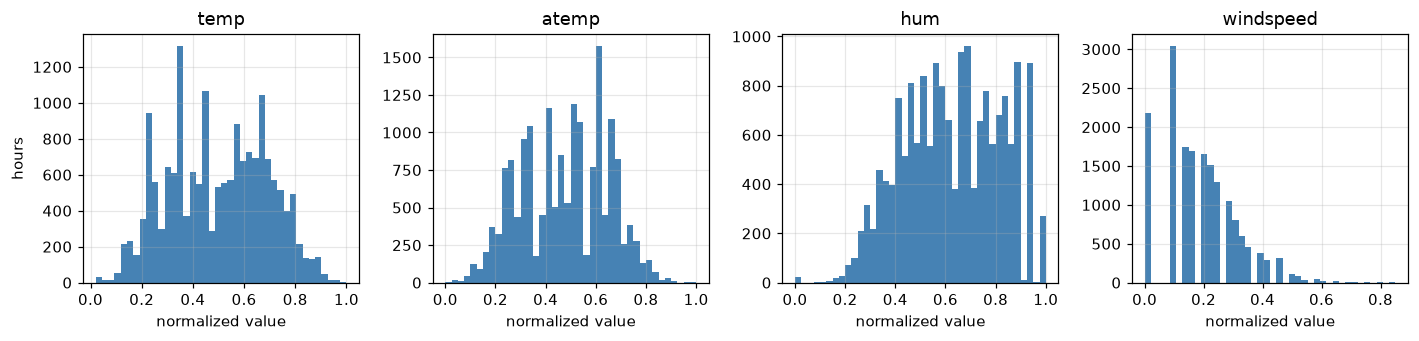

In [18]:
fig, axes = plt.subplots(1, 4, figsize=(13, 3.2))
for ax, c in zip(axes, num_cols):
    ax.hist(df[c], bins=40, color="steelblue")
    ax.set(title=c, xlabel="normalized value")
axes[0].set_ylabel("hours")
plt.tight_layout()

In [ ]:
print("exact-zero rows:")
print({c: int((df[c] == 0).sum()) for c in num_cols})
print()
zero_hum_days = df.loc[df["hum"] == 0, "dteday"].dt.date.value_counts()
print("hum == 0 by date:")
print(zero_hum_days.to_string())

exact-zero rows:
{'temp': 0, 'atemp': 2, 'hum': 22, 'windspeed': 2180}

hum == 0 by date:
dteday
2011-03-10    22


dates with atemp far off its linear relation to temp:
dteday
2012-08-17    24
2011-07-21     5
2011-07-22     3


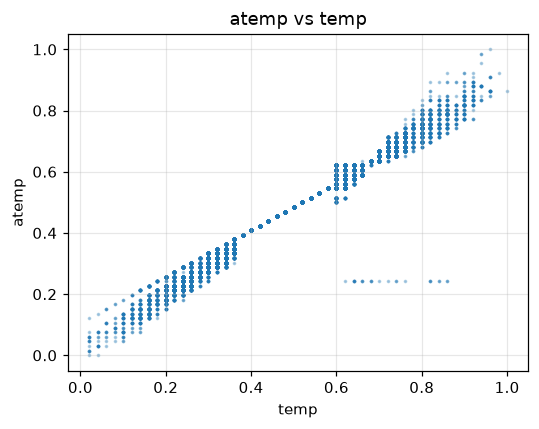

In [ ]:
# atemp is a deterministic function of temp in the source; look for breaks in that relationship
fig, ax = plt.subplots(figsize=(5, 4))
ax.scatter(df["temp"], df["atemp"], s=2, alpha=0.3)
ax.set(title="atemp vs temp", xlabel="temp", ylabel="atemp")
plt.tight_layout()

resid = df["atemp"] - np.poly1d(np.polyfit(df["temp"], df["atemp"], 1))(df["temp"])
odd = df.loc[resid.abs() > 0.1, "dteday"].dt.date.value_counts()
print("dates with atemp far off its linear relation to temp:")
print(odd.to_string())

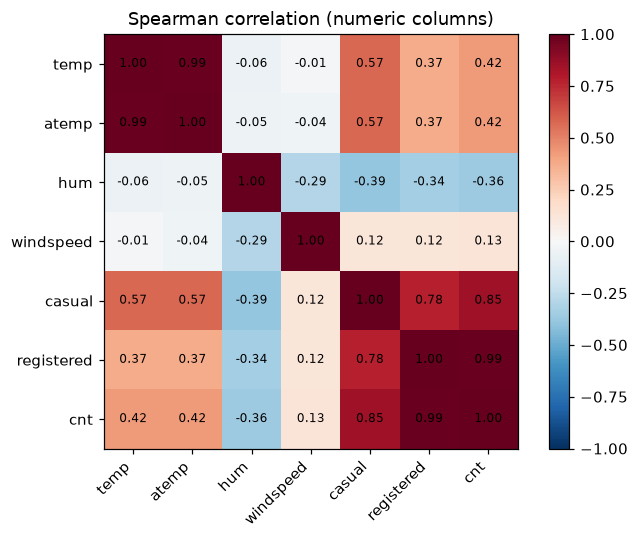

In [ ]:
corr = df[num_cols + ["casual", "registered", "cnt"]].corr(method="spearman")

fig, ax = plt.subplots(figsize=(6.5, 5))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr)))
ax.set_xticklabels(corr.columns, rotation=45, ha="right")
ax.set_yticks(range(len(corr)))
ax.set_yticklabels(corr.columns)
for i in range(len(corr)):
    for j in range(len(corr)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=8)
ax.set_title("Spearman correlation (numeric columns)")
ax.grid(False)
plt.colorbar(im, ax=ax, fraction=0.046)
plt.tight_layout()

## 6. Findings that matter for modeling

**Leakage**
- `casual + registered == cnt` holds for every row. Both are role `Other`, not `Feature`, and `fetch_ucirepo` already excludes them from `data.features`. Never add them back as predictors.
- `instant` is a row index that is monotone in time; it encodes the trend and must stay out of the feature set.

**Time axis**
- 165 of 17,544 hours are absent (0.94%) across 75 gaps; most are isolated night-time hours, but there are a few multi-hour outages, the longest being 36 h starting 2012-10-29 (Hurricane Sandy). The data are not a complete hourly grid, so shift-based lag features (`cnt.shift(24)`) are wrong; lags must be built on the timestamp (reindex to the full grid or merge on `timestamp - 24h`).
- Autocorrelation is strong at lags 1, 24 and 168 (all ≈ 0.82–0.84). Rows are not i.i.d.: use chronological splits and `TimeSeriesSplit` with a gap at least as long as the longest lag used; never `KFold`/`ShuffleSplit`.
- Clear upward trend from 2011 to 2012 (+65% in total rentals year over year), plus strong annual seasonality (summer peak, winter trough). A chronological test set will sit at a higher level than training data; `yr` as a feature cannot extrapolate to unseen years, and level-dependent error metrics (MAE, RMSE) will look different between years.

**Target**
- `cnt` is a non-negative count, right-skewed (skew ≈ 1.3), with heteroskedastic variance (spread grows with the mean). Appropriate choices are a Poisson/Tweedie loss, or fitting on `log1p(cnt)` and back-transforming. Report metrics on the original scale.
- There are no zero-count hours (minimum is 1), so zero inflation is not a concern; `log1p` and `log` are both safe.

**Features**
- `season`, `mnth`, `hr`, `weekday`, `weathersit` are categorical codes stored as integers. Tree models can consume them as-is; linear and distance-based models need one-hot or cyclical (sin/cos) encodings, otherwise hour 23 and hour 0 are treated as maximally distant.
- The hourly profile is bimodal on working days (commute peaks at 8 and 17–18) and unimodal on non-working days. An `hr × workingday` interaction is essential for any model that cannot learn interactions itself.
- `weathersit == 4` occurs in only 3 rows (level 3 has 1,419). Merge it with level 3 or expect unstable estimates for that level.
- `temp` and `atemp` are nearly collinear (ρ ≈ 0.99); one day (2012-08-17) has a constant, incorrect `atemp` for all 24 hours (visible as the horizontal streak in the scatter). Prefer `temp` alone or be aware of the anomaly.
- `hum == 0` for 22 hours on 2011-03-10 is a sensor artifact, not a real reading; treat as missing. `windspeed == 0` is very frequent (~12% of rows) and probably reflects a reporting floor rather than true calm, so it is weakly informative.
- Weather variables are already min-max normalized by the provider using fixed constants; do not re-scale with statistics fitted on the test period.

**Scale**
- 17,379 rows × 12 usable features: every reasonable model trains in seconds. Spend effort on validation protocol and features, not on compute.